# 05 – Part 3: Diversity and popularity bias

We use MMR to re-rank recommendations from our Part 2 ALS model. The aim is to see how much genre diversity improves and what happens to accuracy and popularity bias.


## 1. Setup

Load the existing project configuration and data from the repository.


In [ ]:
from pathlib import Path
import os

if not Path("config.yaml").exists() and Path("../config.yaml").exists():
    os.chdir("..")

assert Path("config.yaml").exists(), "Open this notebook from the Group 16 repository."
assert Path("src/part3_mmr.py").exists(), "Missing src/part3_mmr.py."
assert Path("data/ml-1m/ratings.dat").exists(), "MovieLens 1M is required in data/ml-1m."


## 2. ALS and MMR

We use the same temporal split and tuned ALS settings as Part 2. For validation, ALS trains on the training set. For final testing, it trains on training + validation.

MMR selects 10 films from the top 100 ALS candidates. It balances the ALS score with similarity to films already selected. We use movie genres and **Jaccard similarity**; the distance measure is **1 − Jaccard similarity**. A smaller λ gives more weight to diversity. Since MMR only sees 100 candidates, it cannot introduce films outside that pool.


In [ ]:
import yaml
import pandas as pd

from src.model import Dataset
from src.data.splitting import split
from src.model.implicit_models import ImplicitALS
from src.part3_mmr import mmr_rerank

# Load project configuration and MovieLens data
with open("config.yaml") as f:
    cfg = yaml.safe_load(f)

data = Dataset.from_config("data/ml-1m", cfg["load"])
s = split(data, cfg["split"])

# Train ALS using training data
model = ImplicitALS(**cfg["models"]["implicit_als"])
model.train(s.train)


## 3. Accuracy and diversity on validation

We test λ = 1.0, 0.7, 0.5 and 0.3. **NDCG@10** measures ranking accuracy and **ILD** measures average pairwise genre distance. Higher values are better for both. This validation comparison uses users with training history and relevant validation items.


In [ ]:
import numpy as np
import pandas as pd
from itertools import combinations
from src.evaluation import ndcg_at_k, relevant_by_user

relevant = relevant_by_user(
    s.val.ratings, cfg["evaluation"]["relevance_threshold"]
)

train_users = set(s.train.ratings["user_id"])
valid_users = sorted(set(relevant) & train_users)

genre_map = {
    i: set(g)
    for i, g in zip(data.movies["item_id"], data.movies["genres"])
}

def diversity(recs):
    pairs = list(combinations(recs, 2))
    if not pairs:
        return 0.0

    distances = []
    for a, b in pairs:
        x, y = genre_map[a], genre_map[b]
        similarity = len(x & y) / len(x | y) if (x | y) else 0
        distances.append(1 - similarity)

    return np.mean(distances)

results = []

for lam in [1.0, 0.7, 0.5, 0.3]:
    ndcgs, diversities = [], []

    for u in valid_users:
        recs = mmr_rerank(
            model, u, data.movies,
            top_k=10, candidate_count=100,
            lambda_rel=lam
        )
        ndcgs.append(ndcg_at_k(recs, relevant[u], 10))
        diversities.append(diversity(recs))

    results.append({
        "lambda": lam,
        "NDCG@10": np.mean(ndcgs),
        "ILD": np.mean(diversities)
    })

comparison = pd.DataFrame(results)
print(comparison.round(4).to_string(index=False))

 lambda  NDCG@10    ILD
    1.0   0.1335 0.7692
    0.7   0.1269 0.8416
    0.5   0.1185 0.8945
    0.3   0.1074 0.9298


**What it shows**
- At λ=1.0, NDCG@10 is highest (0.1335), but ILD is lowest (0.7692).
- Reducing λ to 0.7 raises ILD to 0.8416 while NDCG@10 falls to 0.1269.
- With λ=0.3, the list is most diverse (ILD 0.9298), but accuracy is lowest (NDCG@10 0.1074).
- The result is an accuracy–diversity trade-off, not an improvement in both measures.

## 4. Accuracy–diversity graph

Each point shows the validation NDCG and ILD for one λ.


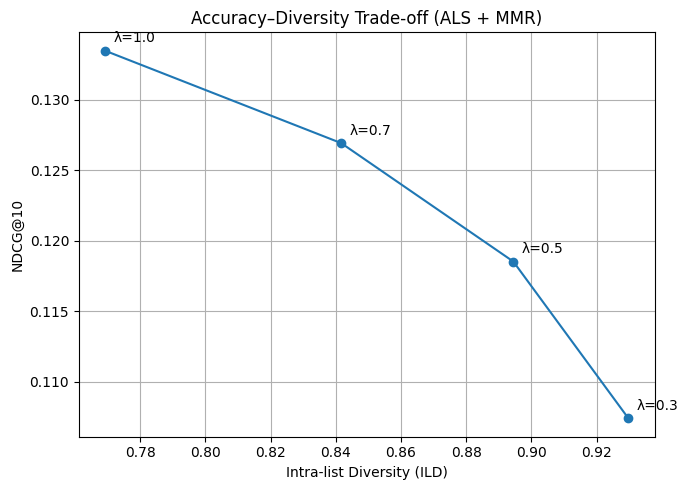

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(7, 5))

plt.plot(comparison["ILD"], comparison["NDCG@10"], marker="o")

for _, row in comparison.iterrows():
    plt.annotate(
        f"λ={row['lambda']:.1f}",
        (row["ILD"], row["NDCG@10"]),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.xlabel("Intra-list Diversity (ILD)")
plt.ylabel("NDCG@10")
plt.title("Accuracy–Diversity Trade-off (ALS + MMR)")
plt.grid(True)
plt.tight_layout()

Path("results").mkdir(exist_ok=True)
plt.savefig("results/part3_accuracy_diversity.png", dpi=150)
plt.show()

**What it shows**
- As λ decreases, the points move right and down: more genre variety comes with lower NDCG@10.
- The change from λ=1.0 to 0.7 gives a noticeable diversity increase with a smaller accuracy decrease than the more aggressive settings.
- We select **λ=0.7** as a practical compromise. This is a judgement based on the validation curve, not a claim that it is best on every metric.

## 5. Coverage and Gini

Coverage is the share of the entire movie catalogue recommended at least once (higher is better). Gini measures how unevenly recommendations are distributed across movies (lower is better).


In [ ]:
from collections import Counter
from src.evaluation import catalogue_coverage

catalogue = set(data.movies["item_id"])

def gini_exposure(recs):
    counts = Counter(i for r in recs.values() for i in r)
    values = np.sort(np.array(
        [counts.get(i, 0) for i in catalogue], dtype=float
    ))
    n = len(values)
    if values.sum() == 0:
        return 0.0
    return (2 * np.sum(np.arange(1, n + 1) * values)
            / (n * values.sum()) - (n + 1) / n)

recommendations_by_lambda = {}
rows = []

for lam in comparison["lambda"]:
    recs = {
        u: mmr_rerank(model, u, data.movies, 10, 100, lam)
        for u in valid_users
    }
    recommendations_by_lambda[lam] = recs

    rows.append({
        "lambda": lam,
        "Coverage": catalogue_coverage(recs, catalogue, 10),
        "Gini": gini_exposure(recs)
    })

coverage_results = pd.DataFrame(rows)
print(coverage_results.round(4).to_string(index=False))

 lambda  Coverage   Gini
    1.0    0.1141 0.9553
    0.7    0.1115 0.9568
    0.5    0.1113 0.9586
    0.3    0.1177 0.9584


**What it shows**
- At λ=0.7, coverage decreases from 0.1141 to 0.1115 compared with λ=1.0.
- Gini increases slightly from 0.9553 to 0.9568, so exposure becomes marginally *more* concentrated, not less.
- λ=0.3 has the highest coverage in this sweep (0.1177), although its Gini remains high (0.9584).
- MMR improves **within-list** genre variety, but it does not reliably reduce **catalogue-wide** popularity concentration. Reranking only 100 ALS candidates may be one contributing limitation; we have not tested that explanation.

## 6. Genre calibration

We compare the genre distribution of users' positive training ratings (at least 4 stars) with that of their recommendations. We report squared Jensen–Shannon distance; lower is better. This is available for 492 validation users.


In [ ]:
from scipy.spatial.distance import jensenshannon
from collections import Counter

all_genres = sorted(set().union(*genre_map.values()))

def genre_distribution(items):
    counts = Counter(
        genre
        for item in items
        for genre in genre_map.get(item, set())
    )
    values = np.array([counts[g] for g in all_genres], dtype=float)
    return values / values.sum() if values.sum() else None

# User preferences from positive training ratings
liked = s.train.ratings[
    s.train.ratings["rating"] >= 4
].groupby("user_id")["item_id"].apply(list).to_dict()

rows = []

for lam, recs in recommendations_by_lambda.items():
    errors = []

    for u, recommended in recs.items():
        profile = genre_distribution(liked.get(u, []))
        output = genre_distribution(recommended)

        if profile is not None and output is not None:
            error = jensenshannon(profile, output, base=2) ** 2
            errors.append(error)

    rows.append({
        "lambda": lam,
        "Calibration Error": np.mean(errors),
        "Users": len(errors)
    })

calibration_results = pd.DataFrame(rows)
print(calibration_results.round(4).to_string(index=False))

 lambda  Calibration Error  Users
    1.0             0.1646    492
    0.7             0.1389    492
    0.5             0.1357    492
    0.3             0.1451    492


**What it shows**
- At λ=0.7, calibration error falls from 0.1646 to 0.1389 relative to λ=1.0.
- λ=0.5 has the lowest calibration error in our sweep (0.1357), but its NDCG@10 is also lower (0.1185).
- At λ=0.3 calibration becomes worse again (0.1451), although diversity is highest.
- This suggests that adding some genre variety can better match a user's past preferences, but maximising variety alone does not guarantee better calibration.

## 7. Validation results

We compare all metrics and choose λ using validation results, not the test set.


In [ ]:
final_table = (
    comparison
    .merge(coverage_results, on="lambda")
    .merge(calibration_results, on="lambda")
)

print(final_table.round(4).to_string(index=False))

final_table.to_csv("results/part3_validation_results.csv", index=False)

 lambda  NDCG@10    ILD  Coverage   Gini  Calibration Error  Users
    1.0   0.1335 0.7692    0.1141 0.9553             0.1646    492
    0.7   0.1269 0.8416    0.1115 0.9568             0.1389    492
    0.5   0.1185 0.8945    0.1113 0.9586             0.1357    492
    0.3   0.1074 0.9298    0.1177 0.9584             0.1451    492


**What it shows**
- λ=1.0 has the strongest validation NDCG, while λ=0.3 has the highest ILD and coverage.
- λ=0.5 has the lowest calibration error but gives up more ranking accuracy than λ=0.7.
- We choose **λ=0.7** to gain substantial diversity and better calibration without the larger accuracy drop of λ=0.5 or 0.3.
- This operating choice does **not** improve every measure: coverage and Gini both move slightly in the wrong direction.

## 8. Final test results

We train ALS on training + validation and compare λ=1.0 with the selected λ=0.7 on the test set. The test includes users with relevant test ratings, whereas the validation comparison used warm users. Therefore, we compare λ values **within** each split, not validation scores directly against test scores.


In [ ]:
# Train the final ALS model on train + validation
final_history = s.train.with_ratings(
    pd.concat([s.train.ratings, s.val.ratings], ignore_index=True)
)

final_model = ImplicitALS(**cfg["models"]["implicit_als"])
final_model.train(final_history)

# Final test users and their relevant movies
test_relevant = relevant_by_user(
    s.test.ratings, cfg["evaluation"]["relevance_threshold"]
)
test_users = sorted(test_relevant)

# Genre preferences from training history only
final_liked = (
    final_history.ratings[final_history.ratings["rating"] >= 4]
    .groupby("user_id")["item_id"]
    .apply(list).to_dict()
)

def evaluate_final(lam):
    recs = {
        u: mmr_rerank(final_model, u, data.movies, 10, 100, lam)
        for u in test_users
    }

    errors = []
    for u, items in recs.items():
        profile = genre_distribution(final_liked.get(u, []))
        recommended = genre_distribution(items)
        if profile is not None and recommended is not None:
            errors.append(jensenshannon(profile, recommended, base=2)**2)

    return {
        "lambda": lam,
        "NDCG@10": np.mean([
            ndcg_at_k(recs[u], test_relevant[u], 10) for u in test_users
        ]),
        "ILD": np.mean([
            diversity(r) for r in recs.values() if len(r) >= 2
        ]),
        "Coverage": catalogue_coverage(recs, catalogue, 10),
        "Gini": gini_exposure(recs),
        "Calibration Error": np.mean(errors)
    }

# Compare original ranking with selected MMR setting
test_results = pd.DataFrame([
    evaluate_final(1.0),
    evaluate_final(0.7)
])

print(test_results.round(4).to_string(index=False))
test_results.to_csv("results/part3_test_results.csv", index=False)

 lambda  NDCG@10    ILD  Coverage   Gini  Calibration Error
    1.0   0.2301 0.7595    0.1342 0.9549             0.1623
    0.7   0.2252 0.8393    0.1293 0.9571             0.1395


**What it shows**
- NDCG@10 decreases slightly from 0.2301 to 0.2252.
- ILD increases from 0.7595 to 0.8393, so recommended films have more varied genres.
- Calibration error decreases from 0.1623 to 0.1395, meaning the recommended genre mix is closer to users' past preferences.
- Coverage falls from 0.1342 to 0.1293, while Gini increases from 0.9549 to 0.9571. We did not improve overall catalogue exposure.

We choose λ=0.7 as a compromise: it gives better diversity with a small loss in accuracy. Users who prefer the most accurate ranking pay that cost. This result does not show a reduction in popularity bias.
